# Лабораторная работа 1. Сравнение LSTM и GRU
Оспан Әсел Ғалымжанқызы · Казахский национальный университет имени аль-Фараби

Создайте временной ряд, разделите его до нарезки окон, обучите обе модели и сравните их с постоянным прогнозом. Требуется PyTorch. Данные генерируются локально. Блокнот содержит все функции скрипта, нужные для опыта.

## Ряд и архитектуры
Вход модели имеет форму (B, 50, 1), цель имеет форму (B, 10, 1). Временные части [0, 6000), [6000, 7500) и [7500, 9000) обрабатываются отдельно. Число скользящих окон равно длине части минус 60 плюс 1.

In [1]:
"""Сопоставление GRU, LSTM и прогноза последним наблюдением."""
from copy import deepcopy
from statistics import mean
from time import perf_counter

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


def make_series(length=9000, seed=42):
    generator = torch.Generator().manual_seed(seed)
    t = torch.arange(length, dtype=torch.float32)
    return torch.sin(0.04 * t) + 0.1 * torch.randn(length, generator=generator)


def windows(series, back=50, horizon=10):
    frames = series.unfold(0, back + horizon, 1)
    return frames[:, :back, None].contiguous(), frames[:, back:, None].contiguous()


class Forecaster(nn.Module):
    def __init__(self, name, hidden=64, horizon=10):
        super().__init__()
        cell = {'GRU': nn.GRU, 'LSTM': nn.LSTM}[name]
        self.cell = cell(1, hidden, batch_first=True)
        self.head = nn.Linear(hidden, horizon)

    def forward(self, x):
        sequence, _ = self.cell(x)
        return self.head(sequence[:, -1, :]).unsqueeze(-1)


def persistence(x, horizon=10):
    return x[:, -1:, :].expand(-1, horizon, -1)


def evaluate(prediction, target):
    residual = prediction - target
    return residual.square().mean().sqrt().item(), residual.abs().mean().item()


@torch.inference_mode()
def forecast(model, x):
    model.eval()
    device = next(model.parameters()).device
    return torch.cat([model(part.to(device)).cpu() for part in x.split(256)])

In [2]:
small = torch.arange(6, dtype=torch.float32)
x, y = windows(small, back=3, horizon=2)
assert x[:, :, 0].tolist() == [[0, 1, 2], [1, 2, 3]]
assert y[:, :, 0].tolist() == [[3, 4], [4, 5]]
series = make_series()
parts = [windows(v) for v in (series[:6000], series[6000:7500], series[7500:])]
print([(tuple(x.shape), tuple(y.shape)) for x, y in parts])
assert [len(x) for x, _ in parts] == [5941, 1441, 1441]

[((5941, 50, 1), (5941, 10, 1)), ((1441, 50, 1), (1441, 10, 1)), ((1441, 50, 1), (1441, 10, 1))]


## Обучение
Валидационная RMSE определяет лучшую эпоху каждой конфигурации. Сравнение на тесте происходит после выбора конфигурации. Параметр FULL запускает десять эпох и три размера батча для каждой сети. Установите FULL = False для короткой технической проверки. Сохраните все шесть строк для отчёта.

In [3]:
def fit(name, batch, epochs, train, val, device):
    torch.manual_seed(42)
    generator = torch.Generator().manual_seed(42)
    loader = DataLoader(TensorDataset(*train), batch_size=batch,
                        shuffle=True, generator=generator)
    model = Forecaster(name).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()
    best_loss, best_epoch, best_state = float('inf'), 0, None
    times = []
    for epoch in range(1, epochs + 1):
        model.train()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = perf_counter()
        for x, y in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x.to(device)), y.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        times.append(perf_counter() - start)
        val_rmse, _ = evaluate(forecast(model, val[0]), val[1])
        if val_rmse < best_loss:
            best_loss, best_epoch = val_rmse, epoch
            best_state = deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    info = dict(model=name, batch=batch, best_epoch=best_epoch,
                val_rmse=best_loss, seconds_per_epoch=mean(times),
                parameters=sum(p.numel() for p in model.parameters()))
    return model, info


def experiment(epochs=10, batches=(16, 64, 256), device=None):
    if epochs < 1 or any(batch < 1 for batch in batches) or not batches:
        raise ValueError('Укажите положительное число эпох и размеры батча.')
    device = torch.device(device or ('cuda' if torch.cuda.is_available() else 'cpu'))
    if device.type == 'cpu':
        torch.set_num_threads(2)
    series = make_series()
    train, val, test = (windows(part) for part in
                        (series[:6000], series[6000:7500], series[7500:]))
    runs = [fit(name, batch, epochs, train, val, device)
            for name in ('GRU', 'LSTM') for batch in batches]
    winner = min((info for _, info in runs), key=lambda info: info['val_rmse'])
    baseline_rmse, baseline_mae = evaluate(persistence(test[0]), test[1])
    for model, info in runs:
        info['selected_by_val'] = info is winner
        predictions = forecast(model, test[0])
        info['test_rmse'], info['test_mae'] = evaluate(predictions, test[1])
        if info is winner:
            trace = (test[1], predictions, persistence(test[0]))
    print(f'{device}: persistence RMSE={baseline_rmse:.4f}, MAE={baseline_mae:.4f}')
    return [info for _, info in runs], trace

In [4]:
FULL = True
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
rows, (truth, forecast_values, baseline) = experiment(
    epochs=10 if FULL else 1,
    batches=(16, 64, 256) if FULL else (64,),
    device=DEVICE,
)
print('PyTorch', torch.__version__)
for row in rows:
    print(row)

cpu: persistence RMSE=0.2263, MAE=0.1815
PyTorch 2.10.0+cpu
{'model': 'GRU', 'batch': 16, 'best_epoch': 9, 'val_rmse': 0.10292469710111618, 'seconds_per_epoch': 12.830515909999985, 'parameters': 13514, 'selected_by_val': True, 'test_rmse': 0.10610782355070114, 'test_mae': 0.08484148979187012}
{'model': 'GRU', 'batch': 64, 'best_epoch': 10, 'val_rmse': 0.11108651012182236, 'seconds_per_epoch': 5.122458930000039, 'parameters': 13514, 'selected_by_val': False, 'test_rmse': 0.1138506755232811, 'test_mae': 0.09067308157682419}
{'model': 'GRU', 'batch': 256, 'best_epoch': 10, 'val_rmse': 0.12275390326976776, 'seconds_per_epoch': 2.441984319999983, 'parameters': 13514, 'selected_by_val': False, 'test_rmse': 0.12692774832248688, 'test_mae': 0.10083720833063126}
{'model': 'LSTM', 'batch': 16, 'best_epoch': 10, 'val_rmse': 0.10334573686122894, 'seconds_per_epoch': 3.323132069999974, 'parameters': 17802, 'selected_by_val': False, 'test_rmse': 0.10525339096784592, 'test_mae': 0.08379917591810226}


## Разбор прогноза
На одном окне сравните десять будущих значений с прогнозами двух методов. Затем проверьте RMSE для каждого горизонта по всем тестовым окнам. Связь между соседними прогнозами обусловлена перекрытием входных окон.

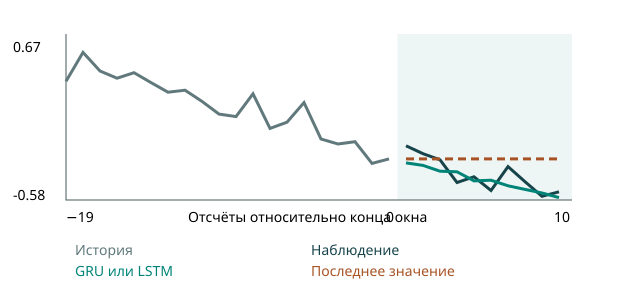

RMSE по горизонту: [0.1077, 0.105, 0.1053, 0.1069, 0.1071, 0.1054, 0.1051, 0.1049, 0.1079, 0.1057]


In [5]:
from IPython.display import SVG, display

window = 75
history = parts[2][0][window, -20:, 0]
series_to_draw = [
    (range(-19, 1), history, '#61797c', 'История', ''),
    (range(1, 11), truth[window, :, 0], '#17444b', 'Наблюдение', ''),
    (range(1, 11), forecast_values[window, :, 0], '#008477', 'GRU или LSTM', ''),
    (range(1, 11), baseline[window, :, 0], '#a85325', 'Последнее значение', '8 5'),
]
all_values = torch.cat([v for _, v, _, _, _ in series_to_draw])
lower, upper = all_values.min().item() - 0.02, all_values.max().item() + 0.02
xpos = lambda t: 66 + 17 * (t + 19)
ypos = lambda v: 200 - 150 * (v - lower) / (upper - lower)
lines = []
for i, (times, values, color, label, dash) in enumerate(series_to_draw):
    points = ' '.join(f'{xpos(t)},{ypos(v):.1f}'
                      for t, v in zip(times, values.tolist()))
    lines.append(f'<polyline points="{points}" fill="none" stroke="{color}" '
                 f'stroke-dasharray="{dash or "none"}" stroke-width="3"/>')
    lines.append(f'<text x="{75 + (i%2)*236}" y="{255 + (i//2)*21}" fill="{color}">{label}</text>')
boundary = (xpos(0) + xpos(1)) / 2
display(SVG(
    '<svg xmlns="http://www.w3.org/2000/svg" width="620" height="294" '
    'font-family="sans-serif" font-size="14">'
    '<rect width="620" height="294" fill="white"/>'
    f'<rect x="{boundary}" y="34" width="{572-boundary}" height="166" fill="#eef6f5"/>'
    '<path d="M66 34 V200 H572" stroke="#48595a" fill="none"/>'
    f'<text x="13" y="52">{upper:.2f}</text><text x="13" y="200">{lower:.2f}</text>'
    f'<text x="{xpos(-19)}" y="222">−19</text><text x="{xpos(0)-3}" y="222">0</text>'
    f'<text x="{xpos(10)-5}" y="222">10</text>'
    '<text x="188" y="222">Отсчёты относительно конца окна</text>'
    + ''.join(lines) + '</svg>'
))
by_horizon = (forecast_values - truth).square().mean(dim=(0, 2)).sqrt()
print('RMSE по горизонту:', [round(v, 4) for v in by_horizon.tolist()])

## Отчёт
Приложите шесть строк метрик, графики нескольких окон, RMSE по горизонту и базовый результат. Укажите устройство и версию PyTorch. Объясните различия во времени и числе шагов. Для заданий B и C следуйте рубрикатору в Lab_01_Deep_Learning.docx.